# E2 — Architecture Comparison: ResNet-18 vs ResNet-50

**Course:** Neural Networks for Computer Vision (HAMK, 5 op)
**Teacher:** Tommi Lahti
**Dataset:** Urban Street Tree Classification (23 classes)

---

## Purpose

E2 trains **ResNet-50** under **identical conditions** to E1 (ResNet-18) and produces:

1. Trained ResNet-50 model
2. Side-by-side comparison table (Accuracy, Precision, Recall, F1)
3. Cross-model Top-k overlay plot
4. Separation point `n` identification

---

## Controlled variables (identical to E1)

| Variable | Value |
|---|---|
| Dataset | `./data/clean_tree` |
| Transforms | Same mild augmentation |
| Loss | CrossEntropyLoss |
| Optimizer | AdamW |
| Head LR | 1e-3 |
| Backbone LR | 1e-4 |
| Weight decay | 1e-4 |
| Batch size | 32 |
| Head epochs | 3 |
| Fine-tune epochs | 20 |
| Early stopping patience | 5 |
| Seed | 42 |

**Only variable changed:** architecture (ResNet-18 → ResNet-50)

---

## Test-set policy

```text
TRAIN → VALIDATION (model selection) → FREEZE → TEST ONCE
```

The test set is evaluated exactly once after the best checkpoint is selected.

## 1. Imports, Seed, Device

In [22]:
import os
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)

SEED = 42

def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device :", DEVICE)

PyTorch: 2.14.1
Device : mps


## 2. Configuration (identical to E1)

In [ ]:
BASE_DIR = Path(".").resolve()
DATA_DIR = BASE_DIR / "data"
TRAIN_DIR = DATA_DIR / "clean_tree" / "train"
VAL_DIR = DATA_DIR / "clean_tree" / "val"
TEST_DIR = DATA_DIR / "clean_tree" / "test"

OUTPUT_DIR = BASE_DIR / "outputs" / "dan" / "training"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- FIX: Correct paths to shared and E1 artifacts ---
DAN_OUTPUTS_DIR = BASE_DIR / "outputs" / "dan"
RESULTS_PATH = DAN_OUTPUTS_DIR / "experiment_results.csv"           # Shared registry
E1_TOPK_PATH = DAN_OUTPUTS_DIR / "training_baseline" / "resnet18_E1_topk.json" # E1 Top-k file
EXPECTED_NUM_CLASSES = 23
BATCH_SIZE = 32
NUM_WORKERS = 0 
PIN_MEMORY = DEVICE.type == "cuda"

HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 20
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 1e-4
LR_FACTOR = 0.5
LR_PATIENCE = 3
EARLY_STOPPING_PATIENCE = 5

MODEL_NAME = "resnet50"
EXPERIMENT_ID = "E2"

CKPT_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}_{EXPERIMENT_ID}.pth"
TOPK_PATH = OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_topk.json"
RESULTS_PATH = OUTPUT_DIR / "experiment_results.csv"

# E1 artifacts (must exist from E1 run)
E1_TOPK_PATH = DAN_OUTPUTS_DIR / "training_baseline" / "resnet18_E1_topk.json"
E1_RESULTS = RESULTS_PATH  # merged registry

assert TRAIN_DIR.exists(), f"Missing {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Missing {VAL_DIR}"
assert TEST_DIR.exists(), f"Missing {TEST_DIR}"

print("E1 Top-k exists:", E1_TOPK_PATH.exists())
print("Output dir:", OUTPUT_DIR)

E1 Top-k exists: False
Output dir: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training


## 3. Transforms (identical to E1)

In [24]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.RandomResizedCrop(size=224, scale=(0.80, 1.00), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("Transforms created (identical to E1).")

Transforms created (identical to E1).


## 4. Datasets & DataLoaders

In [25]:
train_dataset = ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
val_dataset = ImageFolder(root=str(VAL_DIR), transform=eval_transform)
test_dataset = ImageFolder(root=str(TEST_DIR), transform=eval_transform)

assert len(train_dataset.classes) == EXPECTED_NUM_CLASSES
assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

class_names = train_dataset.classes

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Classes: {len(class_names)}")

Train: 3850 | Val: 401 | Test: 405
Classes: 23


## 5. Model: ResNet-50 + 23-class head

ResNet-50 uses Bottleneck blocks (3 conv layers per block) instead of BasicBlock (2 conv layers).
Feature dimension is 2048 (vs 512 for ResNet-18).

In [26]:
weights = ResNet50_Weights.IMAGENET1K_V1
model = resnet50(weights=weights)

# Freeze backbone for head warmup
for param in model.parameters():
    param.requires_grad = False

in_features = model.fc.in_features  # 2048
model.fc = nn.Sequential(
    nn.Dropout(p=0.2),
    nn.Linear(in_features, EXPECTED_NUM_CLASSES),
)
model = model.to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Architecture : ResNet-50")
print(f"Feature dim  : {in_features}")
print(f"Total params : {total:,}")
print(f"Trainable    : {trainable:,} (head only)")

Architecture : ResNet-50
Feature dim  : 2048
Total params : 23,555,159
Trainable    : 47,127 (head only)


## 6. Loss, Optimizer, Scheduler

In [27]:
criterion = nn.CrossEntropyLoss()

USE_AMP = DEVICE.type == "cuda"
if USE_AMP:
    scaler = torch.amp.GradScaler("cuda")
else:
    try:
        scaler = torch.amp.GradScaler("cpu", enabled=False)
    except TypeError:
        scaler = torch.cuda.amp.GradScaler(enabled=False)

def make_optimizer(model, backbone_lr, head_lr):
    head_params = list(model.fc.parameters())
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith("fc") and p.requires_grad]
    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": backbone_lr})
    groups.append({"params": head_params, "lr": head_lr})
    return optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

print("Loss: CrossEntropyLoss | Optimizer: AdamW | AMP:", USE_AMP)

Loss: CrossEntropyLoss | Optimizer: AdamW | AMP: False


## 7. Metrics

In [28]:
def calculate_metrics(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision_score(labels, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(labels, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(labels, predictions, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted", zero_division=0),
    }

print("Metrics ready.")

Metrics ready.


## 8. Training & Evaluation Functions

In [29]:
def set_backbone_batchnorm_eval(model):
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

def train_one_epoch(model, loader, criterion, optimizer, scaler, device, use_amp, head_warmup=False):
    model.train()
    if head_warmup:
        set_backbone_batchnorm_eval(model)
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        if use_amp:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device, use_amp):
    model.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if use_amp:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
        running_loss += loss.item() * labels.size(0)
        all_preds.append(outputs.argmax(1).cpu())
        all_labels.append(labels.cpu())
        total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    metrics = calculate_metrics(all_labels, all_preds)
    metrics["loss"] = running_loss / total
    metrics["predictions"] = all_preds
    metrics["labels"] = all_labels
    return metrics

@torch.no_grad()
def compute_topk(model, loader, device, use_amp, k_values):
    model.eval()
    max_k = min(max(k_values), EXPECTED_NUM_CLASSES)
    top_k_correct = {k: 0 for k in k_values}
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if use_amp:
            with torch.autocast(device_type="cuda"):
                outputs = model(images)
        else:
            outputs = model(images)
        topk = outputs.topk(k=max_k, dim=1).indices
        total += labels.size(0)
        for k in k_values:
            top_k_correct[k] += (topk[:, :k] == labels.unsqueeze(1)).any(1).sum().item()
    return {k: top_k_correct[k] / total for k in k_values}

print("Functions ready.")

Functions ready.


## 9. Train ResNet-50

Stage 1: Head warmup (3 epochs, backbone frozen)
Stage 2: Full fine-tuning (up to 20 epochs, early stopping)

In [30]:
history = {"stage": [], "epoch": [], "train_loss": [], "train_acc": [],
           "val_loss": [], "val_acc": [], "val_f1_macro": [], "learning_rate": []}

best_val_f1 = -1.0
best_val_acc = -1.0
best_val_loss = float("inf")
epochs_no_improve = 0

def is_better(f1, acc, loss):
    if f1 > best_val_f1: return True
    if f1 == best_val_f1 and acc > best_val_acc: return True
    if f1 == best_val_f1 and acc == best_val_acc and loss < best_val_loss: return True
    return False

def save_ckpt(model, epoch, stage, vm):
    torch.save({
        "model_state_dict": model.state_dict(),
        "classes": class_names,
        "epoch": epoch, "stage": stage,
        "experiment": EXPERIMENT_ID, "model_name": MODEL_NAME,
        "val_loss": vm["loss"], "val_accuracy": vm["accuracy"],
        "val_precision_macro": vm["precision_macro"],
        "val_recall_macro": vm["recall_macro"],
        "val_f1_macro": vm["f1_macro"],
        "val_balanced_accuracy": vm["balanced_accuracy"],
        "seed": SEED,
    }, CKPT_PATH)

# ===== STAGE 1: HEAD WARMUP =====
print("=" * 60)
print(f"STAGE 1 — HEAD WARMUP ({HEAD_EPOCHS} epochs)")
print("=" * 60)

optimizer = make_optimizer(model, backbone_lr=0.0, head_lr=HEAD_LR)

for epoch in range(1, HEAD_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE, USE_AMP, head_warmup=True)
    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    history["stage"].append("head"); history["epoch"].append(epoch)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(vm["loss"]); history["val_acc"].append(vm["accuracy"])
    history["val_f1_macro"].append(vm["f1_macro"]); history["learning_rate"].append(HEAD_LR)
    if is_better(vm["f1_macro"], vm["accuracy"], vm["loss"]):
        best_val_f1, best_val_acc, best_val_loss = vm["f1_macro"], vm["accuracy"], vm["loss"]
        save_ckpt(model, epoch, "head", vm)
    print(f"Head {epoch:02d}/{HEAD_EPOCHS} | tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
          f"val_loss={vm['loss']:.4f} val_acc={vm['accuracy']:.4f} F1={vm['f1_macro']:.4f} | {time.time()-t0:.0f}s")

# ===== STAGE 2: FULL FINE-TUNING =====
print("\n" + "=" * 60)
print(f"STAGE 2 — FULL FINE-TUNING (up to {FINETUNE_EPOCHS} epochs)")
print("=" * 60)

for param in model.parameters():
    param.requires_grad = True

optimizer = make_optimizer(model, backbone_lr=BACKBONE_LR, head_lr=HEAD_LR * 0.5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE)
epochs_no_improve = 0

for epoch in range(1, FINETUNE_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE, USE_AMP, head_warmup=False)
    vm = evaluate(model, val_loader, criterion, DEVICE, USE_AMP)
    scheduler.step(vm["loss"])
    lr = optimizer.param_groups[0]["lr"]
    history["stage"].append("ft"); history["epoch"].append(epoch)
    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(vm["loss"]); history["val_acc"].append(vm["accuracy"])
    history["val_f1_macro"].append(vm["f1_macro"]); history["learning_rate"].append(lr)

    if is_better(vm["f1_macro"], vm["accuracy"], vm["loss"]):
        best_val_f1, best_val_acc, best_val_loss = vm["f1_macro"], vm["accuracy"], vm["loss"]
        epochs_no_improve = 0
        save_ckpt(model, epoch, "finetune", vm)
        marker = " *"
    else:
        epochs_no_improve += 1
        marker = "  "

    print(f"FT {epoch:02d}/{FINETUNE_EPOCHS}{marker} | tr_loss={tr_loss:.4f} tr_acc={tr_acc:.4f} | "
          f"val_loss={vm['loss']:.4f} val_acc={vm['accuracy']:.4f} F1={vm['f1_macro']:.4f} | "
          f"lr={lr:.1e} | {time.time()-t0:.0f}s")

    if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

print(f"\nBest val F1: {best_val_f1:.4f} | Best val acc: {best_val_acc:.4f}")
print(f"Checkpoint: {CKPT_PATH}")

STAGE 1 — HEAD WARMUP (3 epochs)
Head 01/3 | tr_loss=2.7691 tr_acc=0.2029 | val_loss=2.1888 val_acc=0.3716 F1=0.3486 | 109s
Head 02/3 | tr_loss=2.1898 tr_acc=0.3623 | val_loss=1.8283 val_acc=0.5012 F1=0.5140 | 106s
Head 03/3 | tr_loss=1.9143 tr_acc=0.4504 | val_loss=1.6991 val_acc=0.5237 F1=0.5334 | 107s

STAGE 2 — FULL FINE-TUNING (up to 20 epochs)
FT 01/20 * | tr_loss=1.0878 tr_acc=0.6761 | val_loss=0.5918 val_acc=0.8155 F1=0.8203 | lr=1.0e-04 | 150s
FT 02/20 * | tr_loss=0.3775 tr_acc=0.8800 | val_loss=0.4530 val_acc=0.8504 F1=0.8472 | lr=1.0e-04 | 148s
FT 03/20 * | tr_loss=0.2155 tr_acc=0.9332 | val_loss=0.4366 val_acc=0.8778 F1=0.8742 | lr=1.0e-04 | 148s
FT 04/20   | tr_loss=0.1613 tr_acc=0.9530 | val_loss=0.6041 val_acc=0.8354 F1=0.8329 | lr=1.0e-04 | 147s
FT 05/20   | tr_loss=0.1506 tr_acc=0.9512 | val_loss=0.4046 val_acc=0.8678 F1=0.8684 | lr=1.0e-04 | 147s
FT 06/20 * | tr_loss=0.1145 tr_acc=0.9639 | val_loss=0.3680 val_acc=0.8903 F1=0.8925 | lr=1.0e-04 | 151s
FT 07/20   | tr_lo

## 10. Test Evaluation (once)

In [31]:
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])

test_metrics = evaluate(model, test_loader, criterion, DEVICE, USE_AMP)
test_preds = test_metrics["predictions"]
test_labels = test_metrics["labels"]

print("=" * 55)
print(f"  E2 TEST RESULTS — ResNet-50")
print("=" * 55)
print(f"  Accuracy          : {test_metrics['accuracy']:.4f}")
print(f"  Precision (macro) : {test_metrics['precision_macro']:.4f}")
print(f"  Recall (macro)    : {test_metrics['recall_macro']:.4f}")
print(f"  F1 (macro)        : {test_metrics['f1_macro']:.4f}")
print(f"  Balanced accuracy : {test_metrics['balanced_accuracy']:.4f}")
print("=" * 55)

  E2 TEST RESULTS — ResNet-50
  Accuracy          : 0.8765
  Precision (macro) : 0.8954
  Recall (macro)    : 0.8897
  F1 (macro)        : 0.8865
  Balanced accuracy : 0.8897


## 11. Top-k Classification (k = 1…10)

In [32]:
k_values = list(range(1, 11))
topk_acc = compute_topk(model, test_loader, DEVICE, USE_AMP, k_values)

print(f"E2 — ResNet-50 — Top-k Test Accuracy")
print("-" * 35)
for k in k_values:
    print(f"  Top-{k:2d}: {topk_acc[k]:.4f}")

topk_payload = {
    "experiment": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "k_values": k_values,
    "top_k_accuracy": {str(k): topk_acc[k] for k in k_values},
}
with open(TOPK_PATH, "w") as f:
    json.dump(topk_payload, f, indent=2)
print(f"\nSaved: {TOPK_PATH}")

E2 — ResNet-50 — Top-k Test Accuracy
-----------------------------------
  Top- 1: 0.8765
  Top- 2: 0.9333
  Top- 3: 0.9605
  Top- 4: 0.9679
  Top- 5: 0.9753
  Top- 6: 0.9827
  Top- 7: 0.9852
  Top- 8: 0.9901
  Top- 9: 0.9901
  Top-10: 0.9951

Saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/resnet50_E2_topk.json


## 12. Cross-Model Comparison: ResNet-18 vs ResNet-50

This section loads E1 results and produces:
1. Side-by-side comparison table
2. Top-k overlay plot
3. Separation point `n` identification

In [33]:
# Load E1 results
e1_row = None
if RESULTS_PATH.exists():
    results_df = pd.read_csv(RESULTS_PATH)
    e1_rows = results_df[results_df["experiment"] == "E1"]
    if len(e1_rows) > 0:
        e1_row = e1_rows.iloc[0]

if e1_row is None:
    print("WARNING: E1 results not found. Run E1 first.")
else:
    print("E1 results loaded.")

# Comparison table
e2_row = {
    "experiment": "E2",
    "model": "resnet50",
    "val_f1_macro": best_val_f1,
    "val_accuracy": best_val_acc,
    "test_accuracy": test_metrics["accuracy"],
    "test_precision_macro": test_metrics["precision_macro"],
    "test_recall_macro": test_metrics["recall_macro"],
    "test_f1_macro": test_metrics["f1_macro"],
    "test_balanced_accuracy": test_metrics["balanced_accuracy"],
}

if e1_row is not None:
    e1_display = {
        "experiment": "E1",
        "model": "resnet18",
        "val_f1_macro": e1_row.get("val_f1_macro", None),
        "val_accuracy": e1_row.get("val_accuracy", None),
        "test_accuracy": e1_row.get("test_accuracy", None),
        "test_precision_macro": e1_row.get("test_precision_macro", None),
        "test_recall_macro": e1_row.get("test_recall_macro", None),
        "test_f1_macro": e1_row.get("test_f1_macro", None),
        "test_balanced_accuracy": e1_row.get("test_balanced_accuracy", None),
    }
    comparison_df = pd.DataFrame([e1_display, e2_row])
else:
    comparison_df = pd.DataFrame([e2_row])

comparison_path = OUTPUT_DIR / "E2_architecture_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("\n" + "=" * 70)
print("  ARCHITECTURE COMPARISON: ResNet-18 vs ResNet-50")
print("=" * 70)
display(comparison_df)
print(f"\nSaved: {comparison_path}")


  ARCHITECTURE COMPARISON: ResNet-18 vs ResNet-50


,experiment,model,val_f1_macro,val_accuracy,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_balanced_accuracy
0,E2,resnet50,0.938489,0.94015,0.876543,0.895371,0.889666,0.886545,0.889666



Saved: /Users/dandev947366/Desktop/HAMK_CLASSES/AI-App-Class/NeuralNetworks-DILIVI/outputs/dan/training/E2_architecture_comparison.csv


## 13. Top-k Overlay Plot & Separation Point

**Project requirement:** *Find the value `n` beyond which the n-best results start to separate the model performance.*

Separation is defined as the first `k` where ResNet-50 exceeds ResNet-18 by ≥ 1 percentage point.

In [38]:
# Load E1 Top-k
e1_topk = None
if E1_TOPK_PATH.exists():
    with open(E1_TOPK_PATH) as f:
        e1_topk = json.load(f)
else:
    print("WARNING: E1 Top-k not found. Cannot produce overlay plot.")

if e1_topk is not None:
    ks = e1_topk["k_values"]
    e1_accs = [e1_topk["top_k_accuracy"][str(k)] for k in ks]
    e2_accs = [topk_acc[k] for k in ks]
    diff = [e2_accs[i] - e1_accs[i] for i in range(len(ks))]

    # Find separation point (first k where diff >= 0.01)
    SEPARATION_MARGIN = 0.01
    separation_k = None
    for k, d in zip(ks, diff):
        if d >= SEPARATION_MARGIN:
            separation_k = k
            break

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(ks, e1_accs, "o-", label="ResNet-18 (E1)", color="tab:blue")
    axes[0].plot(ks, e2_accs, "s-", label="ResNet-50 (E2)", color="tab:orange")
    if separation_k:
        axes[0].axvline(separation_k, color="red", ls="--", alpha=0.7, label=f"separation n={separation_k}")
    axes[0].set_xlabel("k (Top-k)")
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title("Top-k Accuracy: ResNet-18 vs ResNet-50")
    axes[0].set_xticks(ks)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].bar(ks, diff, color="tab:green", alpha=0.7)
    axes[1].axhline(SEPARATION_MARGIN, color="red", ls="--", alpha=0.7, label="margin (1%)")
    axes[1].axhline(0, color="gray", ls="-", alpha=0.3)
    axes[1].set_xlabel("k (Top-k)")
    axes[1].set_ylabel("Δ Accuracy (R50 − R18)")
    axes[1].set_title("Top-k Accuracy Difference")
    axes[1].set_xticks(ks)
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plot_path = OUTPUT_DIR / "E2_topk_comparison_resnet18_vs_resnet50.png"
    plt.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nSeparation margin: {SEPARATION_MARGIN:.0%}")
    if separation_k:
        print(f"Separation point: n = {separation_k}")
        print(f"  → From Top-{separation_k} onward, ResNet-50 exceeds ResNet-18 by ≥ {SEPARATION_MARGIN:.0%}.")
    else:
        print("No clear separation point found (ResNet-50 does not exceed ResNet-18 by ≥ 1% at any k).")

    print(f"\nPlot saved: {plot_path}")

    # Save separation analysis
    sep_payload = {
        "separation_margin": SEPARATION_MARGIN,
        "separation_k": separation_k,
        "k_values": ks,
        "resnet18_topk": {str(k): a for k, a in zip(ks, e1_accs)},
        "resnet50_topk": {str(k): a for k, a in zip(ks, e2_accs)},
        "difference": {str(k): d for k, d in zip(ks, diff)},
    }
    sep_path = OUTPUT_DIR / "E2_topk_separation.json"
    with open(sep_path, "w") as f:
        json.dump(sep_payload, f, indent=2)
    print(f"Separation analysis saved: {sep_path}")

## 14. Confusion Matrix (ResNet-50)

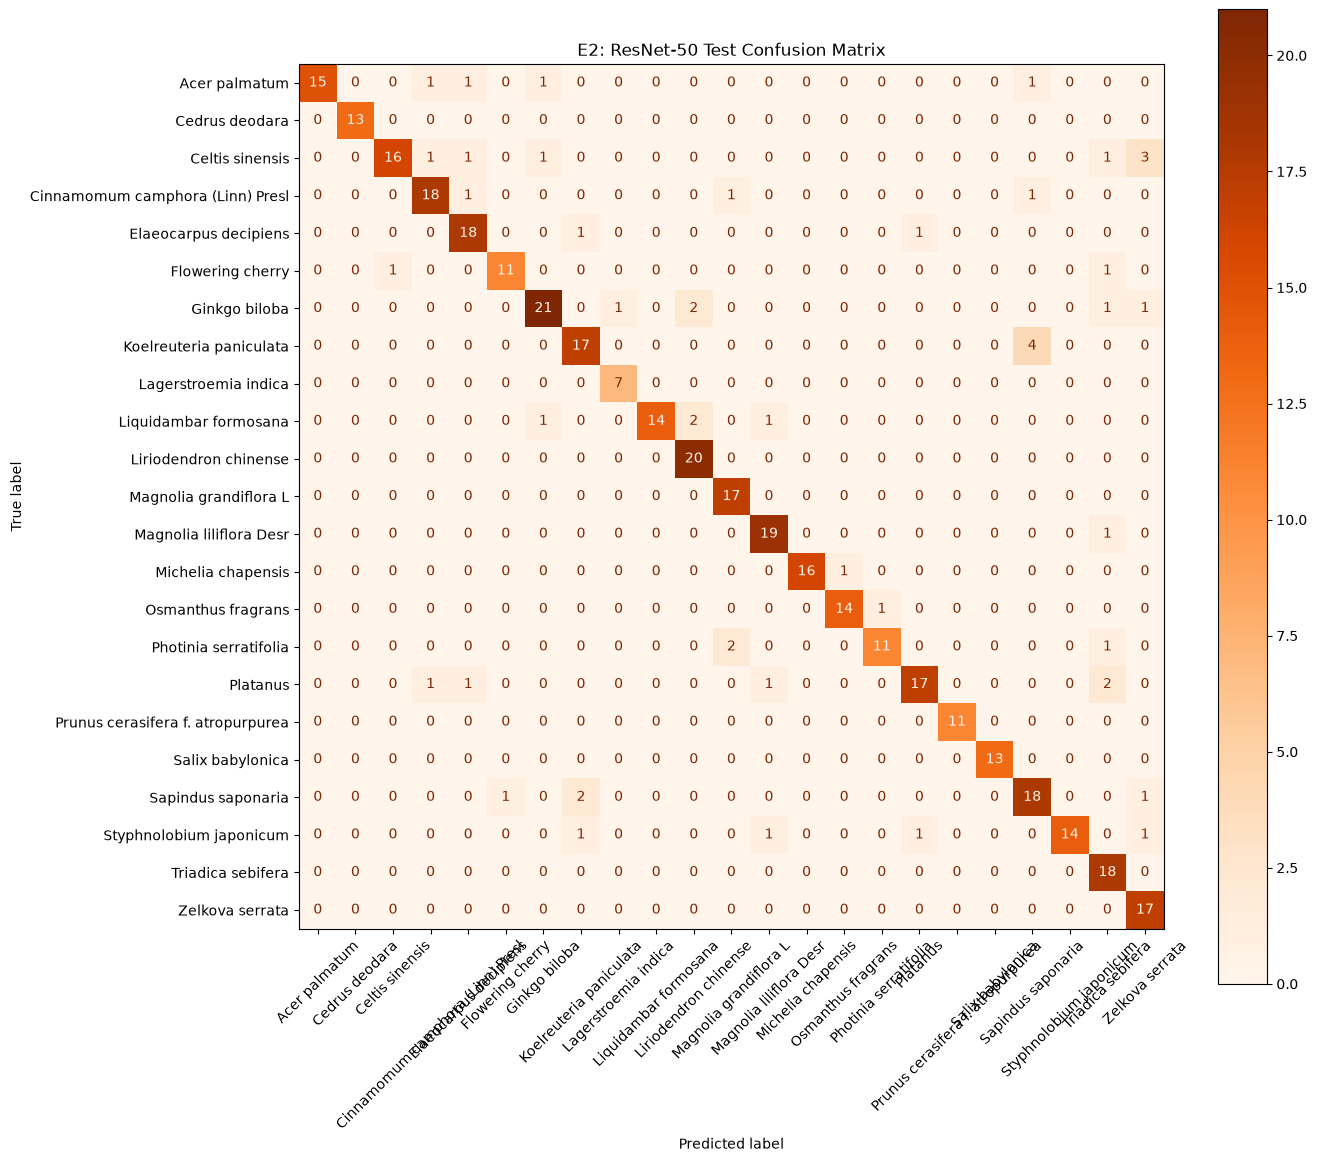

Confusion matrix saved.


In [35]:
cm = confusion_matrix(test_labels, test_preds)
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", cmap="Oranges")
plt.title(f"E2: ResNet-50 Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.png", dpi=150)
plt.show()

pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
    OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_confusion_matrix.csv"
)
print("Confusion matrix saved.")

## 15. Classification Report & Per-Class Metrics

In [36]:
report = classification_report(test_labels, test_preds, target_names=class_names, digits=4, zero_division=0)
print(report)

report_dict = classification_report(test_labels, test_preds, target_names=class_names, output_dict=True, zero_division=0)
per_class_df = pd.DataFrame(report_dict).T
per_class_df = per_class_df.loc[
    [n for n in class_names if n in per_class_df.index],
    ["precision", "recall", "f1-score", "support"],
].sort_values("f1-score")

print("\nPer-class metrics (sorted by F1):")
display(per_class_df)
per_class_df.to_csv(OUTPUT_DIR / f"{MODEL_NAME}_{EXPERIMENT_ID}_per_class.csv")

                                   precision    recall  f1-score   support

                    Acer palmatum     1.0000    0.7895    0.8824        19
                   Cedrus deodara     1.0000    1.0000    1.0000        13
                  Celtis sinensis     0.9412    0.6957    0.8000        23
 Cinnamomum camphora (Linn) Presl     0.8571    0.8571    0.8571        21
            Elaeocarpus decipiens     0.8182    0.9000    0.8571        20
                 Flowering cherry     0.9167    0.8462    0.8800        13
                    Ginkgo biloba     0.8750    0.8077    0.8400        26
          Koelreuteria paniculata     0.8095    0.8095    0.8095        21
             Lagerstroemia indica     0.8750    1.0000    0.9333         7
            Liquidambar formosana     1.0000    0.7778    0.8750        18
            Liriodendron chinense     0.8333    1.0000    0.9091        20
           Magnolia grandiflora L     0.8500    1.0000    0.9189        17
          Magnolia lilif

,precision,recall,f1-score,support
Sapindus saponaria,0.750000,0.818182,0.782609,22.0
Celtis sinensis,0.941176,0.695652,0.800000,23.0
Koelreuteria paniculata,0.809524,0.809524,0.809524,21.0
Platanus,0.894737,0.772727,0.829268,22.0
Triadica sebifera,0.720000,1.000000,0.837209,18.0
Ginkgo biloba,0.875000,0.807692,0.840000,26.0
Photinia serratifolia,0.916667,0.785714,0.846154,14.0
Zelkova serrata,0.739130,1.000000,0.850000,17.0
Cinnamomum camphora (Linn) Presl,0.857143,0.857143,0.857143,21.0
Elaeocarpus decipiens,0.818182,0.900000,0.857143,20.0
